# Privacidad, triaje y evaluación de riesgos 

Analizo los datos personales presentes en soporte y evalúo un triaje por reglas.
El tratamiento del texto se realiza en memoria: **no se muestran ni guardan tickets sin enmascarar**.
Para reproducirlo, ejecutar primero `uv sync` y `uv run novaretail all`.

In [1]:
from pathlib import Path
import os, sys, json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from novaretail import privacy

DATA_DIR = Path(os.getenv("NOVARETAIL_DATA_DIR", ROOT / "data"))
RAW, META = DATA_DIR / "raw", DATA_DIR / "_meta"
FIGURES = ROOT / "docs" / "figuras"
FIGURES.mkdir(parents=True, exist_ok=True)
assert (RAW / "tickets.json").exists(), "Primero ejecuta uv run novaretail all"

with open(RAW / "tickets.json", encoding="utf-8") as f:
    tickets = pd.DataFrame(json.load(f))
customers = pd.read_csv(RAW / "customers.csv", dtype=str)
orders = pd.read_csv(RAW / "orders.csv", dtype=str)
labels = pd.read_csv(META / "tickets_labels.csv", dtype=str)
print(f"Tickets: {len(tickets):,} · Etiquetas de referencia: {len(labels):,}")

Tickets: 3,663 · Etiquetas de referencia: 3,663


## 1. Inventario y finalidad de los datos
El inventario incluye clientes, identificadores vinculables en pedidos y datos de proveedor de facturas. Las bases jurídicas y la conservación propuestas requieren validación formal del DPO. No son plazos impuestos universalmente por ley.

In [2]:
inv = privacy.personal_data_inventory({"customers": customers, "tickets": tickets, "orders": orders})
print(f"Campos identificados: {len(inv)}")
display(inv[["conjunto", "campo", "categoria", "finalidad", "base_legal", "conservacion", "acceso"]])

Campos identificados: 16


,conjunto,campo,categoria,finalidad,base_legal,conservacion,acceso
0,customers,customer_id,Identificador seudónimo,Vincular pedidos y soporte,"Contrato, art. 6.1.b RGPD",Vigencia de relación + revisión DPO,Atención/Operaciones
1,customers,first_name,Identificativo,Identificación y atención,"Contrato, art. 6.1.b RGPD",Vigencia de relación + revisión DPO,Atención
2,customers,last_name,Identificativo,Identificación y atención,"Contrato, art. 6.1.b RGPD",Vigencia de relación + revisión DPO,Atención
3,customers,email,Contacto,Seguimiento de pedidos y soporte,"Contrato, art. 6.1.b RGPD",Vigencia de relación + revisión DPO,Atención
4,customers,phone,Contacto,Notificaciones de entrega,"Contrato, art. 6.1.b RGPD",Vigencia de relación + revisión DPO,Atención/Logística
5,customers,birth_year,Dato demográfico,Análisis agregado; revisar necesidad,Interés legítimo solo si supera ponderación,Eliminar si no es necesario,Analítica restringida
6,customers,postal_code,Localización indirecta,Distribución y entrega,"Contrato, art. 6.1.b RGPD",Vigencia de relación + revisión DPO,Logística
7,customers,region,Localización indirecta,Planificación agregada,"Interés legítimo, previa ponderación",Agregado sin identificadores,Analítica
8,customers,segment,Perfil comercial,Análisis de equidad del servicio,"Interés legítimo, previa ponderación",Revisión periódica; sin exportar PII,DPO/Analítica
9,customers,acquisition_channel,Perfil comercial,Evaluar captación y retención,"Interés legítimo, previa ponderación",Revisión periódica; agregado,Marketing/Analítica


## 2. Enmascarado y auditoría de fuga observable
El texto se enmascara antes de clasificarlo. Los datos de clientes/pedidos se usan solo en esta fase para localizar el nombre completo asociado al ticket. La auditoría inspecciona valores sintéticos conocidos y direcciones con código postal. El **0 % observable no equivale a anonimización garantizada**: las erratas, valores sin formato reconocible y los identificadores de pedido siguen requiriendo controles.

In [3]:
masked = privacy.mask_tickets(tickets, customers, orders)
audit = privacy.audit_masking(tickets, masked, customers, orders)
print("Ejemplo de salida (solo texto ya enmascarado):")
display(masked[["ticket_id", "channel", "text_masked"]].head(4))
display(audit)
print("Fuga observable global:", f"{100*audit.sin_enmascarar.sum()/max(audit.detectadas_original.sum(),1):.2f}%")

Ejemplo de salida (solo texto ya enmascarado):


,ticket_id,channel,text_masked
0,TK000001,email,El producto del pedido NR0000057 ha llegado ro...
1,TK000002,formulario_web,Solicito la devolución del pedido NR0000098. E...
2,TK000003,email,"Hola, quería saber si Cafetera Sierra Mini est..."
3,TK000004,formulario_web,Llevo 2 días esperando el pedido NR0000363. El...


,tipo,detectadas_original,sin_enmascarar,fuga_observable_pct
0,DIRECCION,276,0,0.00
1,DIRECCION_POSTAL,415,0,0.00
2,DNI,490,0,0.00
3,EMAIL,1119,0,0.00
4,IBAN,52,0,0.00
5,NOMBRE,1817,2,0.11
6,TARJETA,99,0,0.00
7,TARJETA_COMPLETA,0,0,0.00
8,TELEFONO,1257,0,0.00


Fuga observable global: 0.04%


## 3. Clasificador por reglas y comparación con las etiquetas del generador
Las etiquetas de control (`data/_meta`) se usan exclusivamente para **evaluar**, nunca para asignar la categoría. La categoría se obtiene solo del texto enmascarado; el segmento del cliente se incorpora después para el análisis de equidad.

In [4]:
pred = privacy.classify_tickets(masked)
pred = privacy.link_ticket_segments(pred, orders, customers)
results = privacy.evaluate_classification(pred, labels)
print(f"Tickets evaluados: {results['n']:,}")
print(f"Exactitud categoría: {results['acierto_categoria_pct']:.2f}%")
print(f"Exactitud prioridad: {results['acierto_prioridad_pct']:.2f}%")
print(f"Recall prioridad alta: {results['recall_alta_pct']:.2f}%")
display(results["por_categoria"])
display(results["por_grupo"])

Tickets evaluados: 3,663
Exactitud categoría: 99.04%
Exactitud prioridad: 75.08%
Recall prioridad alta: 74.89%


,categoria,soporte,precision,recall
0,cambio_direccion,159,1.0,0.9937
1,cancelacion_reembolso,75,1.0,1.0000
2,cobro_duplicado,116,1.0,0.9914
3,consulta_producto,324,1.0,0.9938
4,devolucion,756,1.0,0.9921
5,producto_defectuoso,370,1.0,0.9946
6,proteccion_datos,108,1.0,1.0000
7,queja_atencion,307,1.0,0.9967
8,retraso_entrega,1448,1.0,0.9848
9,sin_clasificar,0,0.0,0.0000


,dimension,grupo,n,error_categoria_pct,error_prioridad_pct
0,channel,chat,982,1.22,24.64
1,channel,email,1399,1.07,25.23
2,channel,formulario_web,446,0.22,26.23
3,channel,redes_sociales,323,0.93,24.77
4,channel,telefono,513,0.78,23.59
5,segmento,estandar,2131,1.03,14.27
6,segmento,premium,1063,0.85,46.10
7,segmento,sin_vincular,469,0.85,25.37


## 4. Diferencias entre canales y segmentos
La comparación es descriptiva y se hace sobre datos sintéticos. Las diferencias entre grupos no demuestran discriminación causal. Las categorías y la prioridad no usan como entrada el segmento, pero las etiquetas del generador sí contemplan el segmento «premium» para algunas prioridades; esa diferencia debe interpretarse como una decisión de política comercial a revisar.

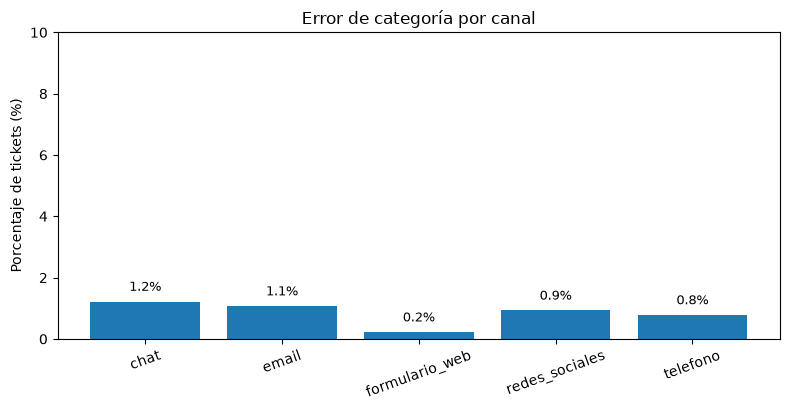

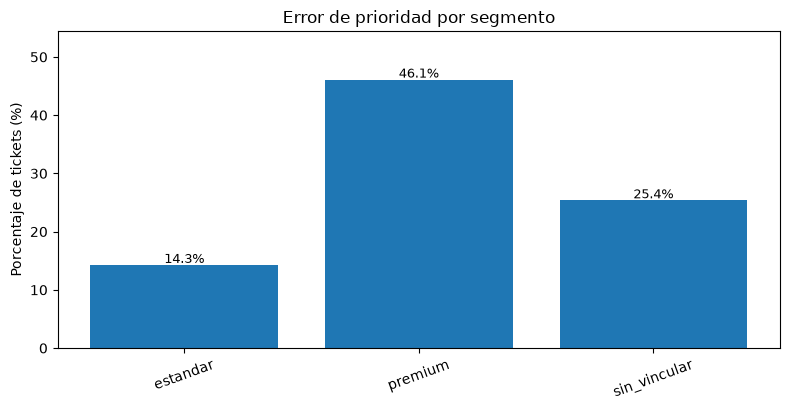

Cobertura de vinculación de segmentos: 87.2%


In [5]:
groups = results["por_grupo"]
for field, image_name, metric, heading in [
    ("channel", "p4_error_categoria_canal.png", "error_categoria_pct", "Error de categoría por canal"),
    ("segmento", "p4_error_prioridad_segmento.png", "error_prioridad_pct", "Error de prioridad por segmento"),
]:
    d = groups[groups["dimension"].eq(field)].copy()
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.bar(d["grupo"], d[metric])
    ax.set_title(heading)
    ax.set_ylabel("Porcentaje de tickets (%)")
    ax.set_ylim(0, max(10, d[metric].max()*1.18))
    ax.tick_params(axis="x", rotation=20)
    for i, value in enumerate(d[metric]):
        ax.text(i, value+0.35, f"{value:.1f}%", ha="center", fontsize=9)
    fig.tight_layout()
    fig.savefig(FIGURES / image_name, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
print("Cobertura de vinculación de segmentos:", f"{100*pred.segmento.ne('sin_vincular').mean():.1f}%")

## 5. Evidencia resumida para la memoria y decisión al DPO

**Hallazgos y controles prioritarios:**

1. La fuga observable debe mantenerse en cero para los patrones auditados, con revisión humana de casos dudosos; no se debe equiparar una regex con anonimización.
2. Los falsos negativos de prioridad alta exigen una cola de revisión humana de tickets no clasificados y una segunda revisión de incidencias sensibles.
3. La diferencia de error por segmento requiere revisar el criterio de prioridad «premium» que se usa en el generador: atender mejor un segmento puede desplazar injustamente casos de otros.
4. El DPO debe aprobar conservación, base jurídica, autorización por roles y transferencias de la futura plataforma cloud.
5. Ante un incidente de seguridad, activar protocolo de contención, análisis y, cuando proceda, notificación conforme al RGPD.

**MAGERIT:** la matriz de amenazas e impacto, con salvaguardas y riesgo residual, se documenta en el apartado 5.6 del Word. La valoración presentada es una estimación del caso, no una auditoría operativa de una empresa real.

In [6]:
print("RESUMEN PARA EL WORD")
print("Dataset sintético: ", results["n"], "tickets")
print("Fuga observable de PII auditada:",
      f"{100*audit.sin_enmascarar.sum()/max(audit.detectadas_original.sum(),1):.2f}%",
      "(alcance limitado a patrones y valores observables)")
print("Acierto categoría:", results["acierto_categoria_pct"], "%")
print("Acierto prioridad:", results["acierto_prioridad_pct"], "%")
print("Recall alta:", results["recall_alta_pct"], "%")
print("Los resultados deben copiarse de esta ejecución final, con uv.lock, al Word.")

RESUMEN PARA EL WORD
Dataset sintético:  3663 tickets
Fuga observable de PII auditada: 0.04% (alcance limitado a patrones y valores observables)
Acierto categoría: 99.04 %
Acierto prioridad: 75.08 %
Recall alta: 74.89 %
Los resultados deben copiarse de esta ejecución final, con uv.lock, al Word.
